# Willamette: dove la regressione aiuta e dove aggiunge errore

Diagnosi **retrospettiva**, dopo il test concluso: 5.213 coppie storiche USGS, ossigeno disciolto a un’ora, quattro finestre del 2025. Nessun nuovo dato, addestramento, soglia scelta o variante prevista. Tutte queste finestre sono ormai dati di sviluppo.

La persistenza ripete l’ultima misura. Il ridge aggiunge una correzione lineare congelata. La regola attuale disattiva quella correzione quando tutti i dodici valori passati pubblicati sono uguali. Uguaglianza pubblicata non significa fiume fisicamente costante.

Questo notebook è il compagno eseguibile di `scripts/diagnose_stability_errors.py`. La documentazione completa è disponibile anche in inglese in `docs/WILLAMETTE_ERROR_MECHANISMS_EN.md`.


## 1. Verificare gli archivi e riprodurre il risultato
Il replay ricostruisce le previsioni già fissate, le esclusioni e gli hash, incluso il commit precedente alla raccolta. Non chiama una procedura di apprendimento. Le date riportate sono UTC; gli estremi delle interrogazioni archiviate sono inclusivi.


In [1]:
from pathlib import Path
import json, sys, math
from html import escape
from IPython.display import display, HTML
ROOT = Path.cwd()
assert (ROOT/'scripts/diagnose_stability_errors.py').exists(), 'Run from repository root'
sys.path.insert(0, str(ROOT/'scripts'))
import diagnose_stability_errors as diagnosis
from audit_stability_compare import assert_same_receipt
report = json.loads((ROOT/diagnosis.OUTPUT).read_bytes())
assert_same_receipt(diagnosis.diagnose(ROOT), report)
P,R,C = report['methods']
labels = {P:'Ultima misura', R:'Ridge congelato', C:'Regola attuale'}
def table(headers, rows):
    display(HTML('<table><thead><tr>'+''.join('<th>'+escape(str(x))+'</th>' for x in headers)+'</tr></thead><tbody>'+''.join('<tr>'+''.join('<td>'+escape(str(x))+'</td>' for x in row)+'</tr>' for row in rows)+'</tbody></table>'))
print('Replay verificato; coppie:', report['pairs'])
print('Nessun nuovo addestramento:', not report['scope']['modelRefitted'])


Replay verificato; coppie: 5213
Nessun nuovo addestramento: True


## 2. Ripartire dal confronto complessivo
La MAE è la media degli errori assoluti. La macro MAE dà lo stesso peso a ciascuna delle quattro finestre, anche se le coppie accettate sono leggermente diverse. La RMSE pesa maggiormente gli errori grandi: non sostituiamo a posteriori il criterio primario MAE.


In [2]:
table(['Finestra UTC (fine inclusiva)','Coppie',*[labels[m]+' MAE mg/L' for m in (P,R,C)]],
      [[s['window']['start']+' / '+s['window']['end'],s['pairs'],*[f"{s['scores'][m]['maeMgL']:.6f}" for m in (P,R,C)]] for s in report['seasonal']])
table(['Metodo','Macro MAE mg/L','Media delle RMSE stagionali mg/L'],
      [[labels[m], f"{report['macro'][m]['maeMgL']:.6f}",f"{report['macro'][m]['rmseMgL']:.6f}"] for m in (P,R,C)])
table(['Metodo','Aiuta','Uguale','Peggiora'],[[labels[m],*[report['comparisonsToPersistence'][m][k] for k in ('wins','ties','losses')]] for m in (R,C)])


Finestra UTC (fine inclusiva),Coppie,Ultima misura MAE mg/L,Ridge congelato MAE mg/L,Regola attuale MAE mg/L
2025-02-01T00:00:00Z / 2025-03-01T00:00:00Z,1276,0.017085,0.028469,0.024586
2025-05-01T00:00:00Z / 2025-05-29T00:00:00Z,1320,0.083333,0.089813,0.089723
2025-06-01T00:00:00Z / 2025-06-29T00:00:00Z,1298,0.201695,0.193600,0.193600
2025-11-01T00:00:00Z / 2025-11-29T00:00:00Z,1319,0.053980,0.062337,0.061973


Metodo,Macro MAE mg/L,Media delle RMSE stagionali mg/L
Ultima misura,0.089023,0.154949
Ridge congelato,0.093555,0.142602
Regola attuale,0.092470,0.142317


Metodo,Aiuta,Uguale,Peggiora
Ridge congelato,1435,0,3778
Regola attuale,1381,533,3299


## 3. Ricostruire il perché del divario sulla MAE
Le categorie «invariato», «salita» e «discesa» guardano il risultato futuro: servono a spiegare, non a decidere una previsione. I contributi sono additivi: sommiamo i guadagni del gruppo, dividiamo per **tutte** le coppie della sua finestra e facciamo la media delle quattro finestre. Le MAE condizionali pooled nella tabella hanno invece come denominatore soltanto il gruppo.

Un guadagno positivo aiuta; un contributo negativo aggiunge errore. La decomposizione dei quadrati è MSE, non RMSE: la radice quadrata non è additiva.


Esito noto dopo,Coppie,MAE ultima mg/L,MAE regola mg/L,Contributo macro MAE mg/L
Valore futuro invariato,2796,0.000000,0.022664,-0.012136
Valore futuro in salita,1200,0.194500,0.165813,+0.006589
Valore futuro in discesa,1217,0.190140,0.181180,+0.002099


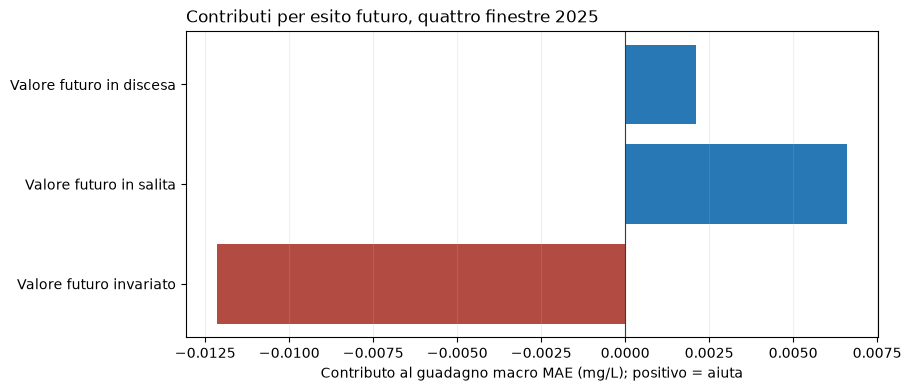

Somma dei contributi, mg/L: -0.003447024


In [3]:
import matplotlib.pyplot as plt
names={'unchanged':'Valore futuro invariato','rise':'Valore futuro in salita','fall':'Valore futuro in discesa'}
groups=report['byFutureOutcome']
table(['Esito noto dopo','Coppie','MAE ultima mg/L','MAE regola mg/L','Contributo macro MAE mg/L'],
      [[names[g['group']],g['pairs'],f"{g['pooledScores'][P]['maeMgL']:.6f}",f"{g['pooledScores'][C]['maeMgL']:.6f}",f"{g['macroMAEGainContributionMgL']:+.6f}"] for g in groups])
total=math.fsum(g['macroMAEGainContributionMgL'] for g in groups)
assert abs(total-(report['macro'][P]['maeMgL']-report['macro'][C]['maeMgL']))<1e-9
fig,ax=plt.subplots(figsize=(9,3.8),layout='constrained')
values=[g['macroMAEGainContributionMgL'] for g in groups]
ax.barh([names[g['group']] for g in groups],values,color=['#B24C42' if v<0 else '#2878B5' for v in values])
ax.axvline(0,color='#353A40',linewidth=.8);ax.set_xlabel('Contributo al guadagno macro MAE (mg/L); positivo = aiuta')
ax.set_title('Contributi per esito futuro, quattro finestre 2025',loc='left')
ax.grid(axis='x',alpha=.2);plt.show()
print('Somma dei contributi, mg/L:',f'{total:+.9f}')


## 4. Due esempi estremi, con le misure storiche
Selezione deterministica: massimo beneficio e massimo danno sul **guadagno MAE individuale** della regola attuale. Non sono casi tipici. Il punto finale osservato è mostrato soltanto per verificare la previsione a posteriori; non entra negli ingressi.


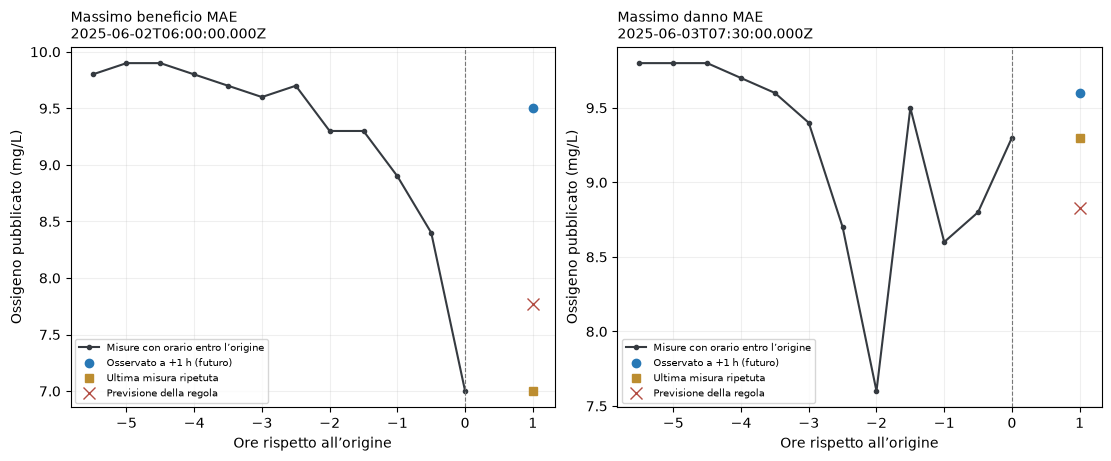

Esempio,Ultima mg/L,Osservato mg/L,Regola mg/L,Errore ultima,Errore regola,Guadagno mg/L
maximumHarm,9.300000,9.600000,8.825073,0.300000,0.774927,-0.474927
maximumBenefit,7.000000,9.500000,7.768627,2.500000,1.731373,+0.768627


In [4]:
from datetime import datetime
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
for ax,key,title in zip(axes,['maximumBenefit','maximumHarm'],['Massimo beneficio MAE','Massimo danno MAE']):
    e=report['examples'][key];history=e['oxygenHistory']
    origin=datetime.fromisoformat(e['origin'].replace('Z','+00:00'))
    x=[(datetime.fromisoformat(h['timeUTC'].replace('Z','+00:00'))-origin).total_seconds()/3600 for h in history]
    ax.plot(x,[h['value'] for h in history],'o-',color='#353A40',label='Misure con orario entro l’origine',markersize=3)
    ax.plot([1],[e['actualMgL']],'o',color='#2878B5',label='Osservato a +1 h (futuro)')
    ax.plot([1],[e['predictionsMgL'][P]],'s',color='#BC8D30',label='Ultima misura ripetuta')
    ax.plot([1],[e['predictionsMgL'][C]],'x',color='#B24C42',label='Previsione della regola',markersize=8)
    ax.axvline(0,color='#777',linestyle='--',linewidth=.8);ax.set_title(title+'\n'+e['origin'],loc='left',fontsize=10)
    ax.set_xlabel('Ore rispetto all’origine');ax.set_ylabel('Ossigeno pubblicato (mg/L)');ax.grid(alpha=.2);ax.legend(fontsize=7)
plt.show()
table(['Esempio','Ultima mg/L','Osservato mg/L','Regola mg/L','Errore ultima','Errore regola','Guadagno mg/L'],
 [[key,f"{e['predictionsMgL'][P]:.6f}",f"{e['actualMgL']:.6f}",f"{e['predictionsMgL'][C]:.6f}",f"{e['absoluteErrorsMgL'][P]:.6f}",f"{e['absoluteErrorsMgL'][C]:.6f}",f"{e['fallbackGainMgL']:+.6f}"] for key,e in report['examples'].items()])


## 5. Spiegare la correzione senza inventare una causa fisica
Ogni contributo è coefficiente × ingresso standardizzato usando soltanto il training del 2024. Somma e intercetta ricostruiscono la correzione. Questa è una spiegazione aritmetica, non dimostra cause ambientali o effetti di un intervento.

Un altro controllo evita una scorciatoia: la MAE come funzione di un moltiplicatore costante delle correzioni è convessa. La derivata destra in zero è positiva in queste finestre. Quindi qualsiasi moltiplicatore costante positivo peggiora la macro MAE rispetto alla persistenza **su questo insieme finito**. Non abbiamo addestrato né cercato un moltiplicatore; non è un teorema su nuovi dati o filtri condizionali.


In [5]:
for key,e in report['examples'].items():
    parts=e['numericalContributionsNotPhysicalCauses']
    print(key, 'intercetta mg/L:', f"{parts['residualInterceptMgL']:+.6f}")
    table(['Ingresso','Valore','Contributo numerico mg/L'],[[p['feature'],f"{p['inputValue']:.6f}",f"{p['contributionMgL']:+.6f}"] for p in parts['contributions']])
    print('Correzione totale mg/L:',f"{parts['totalCorrectionMgL']:+.6f}",'; ingressi fuori range:',e['outsideTrainingFeatures'])
table(['Correzione originale','Derivata destra macro in zero, mg/L'],
      [[labels[m],f"{report['constantAttenuation'][m]['macroRightDerivativeAtZeroMgL']:+.9f}"] for m in (R,C)])


maximumHarm intercetta mg/L: +0.001524


Ingresso,Valore,Contributo numerico mg/L
oxygenNow,9.300000,+0.006647
oxygenDelta30m,0.500000,-0.108046
oxygenDelta2h,1.700000,-0.346651
oxygenDelta5h30m,-0.500000,+0.000698
clockSinUTC,0.923880,-0.017646
clockCosUTC,-0.382683,+0.000309
temperatureNow,18.400000,-0.007199
temperatureDelta2h,-0.200000,-0.004563


Correzione totale mg/L: -0.474927 ; ingressi fuori range: ['oxygenDelta2h']
maximumBenefit intercetta mg/L: +0.001524


Ingresso,Valore,Contributo numerico mg/L
oxygenNow,7.000000,+0.016046
oxygenDelta30m,-1.400000,+0.303107
oxygenDelta2h,-2.300000,+0.470238
oxygenDelta5h30m,-2.800000,+0.003872
clockSinUTC,1.000000,-0.019095
clockCosUTC,0.000000,-0.000019
temperatureNow,18.300000,-0.007028
temperatureDelta2h,0.000000,-0.000016


Correzione totale mg/L: +0.768627 ; ingressi fuori range: ['oxygenNow', 'oxygenDelta30m', 'oxygenDelta2h', 'oxygenDelta5h30m']


Correzione originale,"Derivata destra macro in zero, mg/L"
Ridge congelato,+0.003327639
Regola attuale,+0.002243274


## 6. Prossima decisione da prendere insieme
Proposta ancora aperta: studiare un filtro che usi soltanto informazioni disponibili all’origine e spenga le piccole correzioni. Il taglio descrittivo di 0,05 mg/L nel JSON **non è una soglia scelta o validata**, non misura accuratezza del sensore e non è ecologico.

Prima di un nuovo test: concordare obiettivo, sviluppo temporale e criteri; scegliere una sola regola con dati di sviluppo; congelare regola, implementazione e calendario; valutare una sola volta su dati nuovi, mai usati nelle scelte. Confrontare persistenza, ridge, vecchia regola e nuova candidata sulle stesse origini. Restano da concordare il ruolo dei controlli per finestra e della RMSE e quale miglioramento abbia utilità pratica.

**Limiti:** osservazioni finalizzate retrospettive, una sola stazione soggetta a maree, quattro finestre di 28 giorni; nessun test operativo o disponibilità storica as-of-origin dimostrati. Nessun target osservato sotto la soglia illustrativa di 5 mg/L, nessuna validazione di allarmi, attribuzione degli inquinanti o benefici sul campo. Nessun nuovo intervallo di previsione calibrato.

**Missione Virdacora:** prove ambientali verificabili al servizio delle comunità e dei giovani. Questa diagnosi lascia invariati Oracle operativo, quorum, governance, tesoreria e spese. Prima di ampliare a 24 ore o tre mesi rendiamo controllabile il caso a un’ora.


In [6]:
assert report['scope']=={'postHoc':True,'newFinalValidation':False,'newDataDownloaded':False,'modelRefitted':False,'newForecastRuleEvaluated':False,'operationalModelChanged':False,'nextTestAgreedOrFrozen':False}
assert sum(g['pairs'] for g in report['byFutureOutcome'])==report['pairs']==5213
assert report['macro'][C]['maeMgL']>report['macro'][P]['maeMgL']
print('Confini della diagnosi verificati; nessun prossimo test congelato.')


Confini della diagnosi verificati; nessun prossimo test congelato.
